# EDA on Retail Sales Data
- **Notebook by:** Rishika Sharma
- **Level 1, Task 1**
- **Dataset:** Retail Sales Dataset (Kaggle)
- **Author:** Mohammad Talib
- **Source:** https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset
- **License:** CC0: Public Domain

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Libraries Used
- **Pandas**: data loading, cleaning and analysis.
- **Matplotlib**: basic charts (line, bar, pie).
- **Seaborn**: statistical charts like heatmaps and count plots.

In [2]:
df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
df.shape

(1000, 9)

### Dataset Size
The dataset has **1000 rows** and **9 columns**.

In [4]:
df.dtypes

Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

In [5]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

### Data Types and Missing Values
- Columns include numbers (Age, Quantity, Price per Unit, Total Amount) and text (Gender, Product Category, Customer ID, Date).
- Date is stored as text, so it needs to be converted to datetime format.
- There are **no missing (null) values**, so no cleaning is needed.

In [6]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
stats = df[num_cols].agg(["mean", "median", "std"]).T
stats["mode"] = [df[c].mode()[0] for c in num_cols]
stats

,mean,median,std,mode
Age,41.392,42.0,13.681430,43
Quantity,2.514,3.0,1.132734,4
Price per Unit,179.890,50.0,189.681356,50
Total Amount,456.000,135.0,559.997632,50


### Descriptive Statistics
- The average customer age is about 41 years (median 42), so customers are mostly middle-aged.
- The mean Total Amount (456) is much higher than the median (135). This means a few large orders pull the average up.
- The most common price per unit is 50, and the most common quantity bought is 4.
- Price per Unit and Total Amount have high standard deviations, so order values vary a lot.

In [7]:
df["Date"] = pd.to_datetime(df["Date"])
df.dtypes

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

### Date Conversion
The Date column was converted from text to datetime format. This allows us to extract months and quarters for the time series analysis.

In [8]:
df = df[df["Date"] < "2024-01-01"].copy()
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Quarter
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023-11,2023Q4
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023-02,2023Q1
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023-01,2023Q1
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023-05,2023Q2
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023-05,2023Q2


### Month and Quarter Columns
- I kept only the 2023 data, because there are just two transactions on 1 January 2024 and they would make the monthly chart look odd.
- I also added two new columns, **Month** and **Quarter**, so that sales can be grouped by month and quarter.

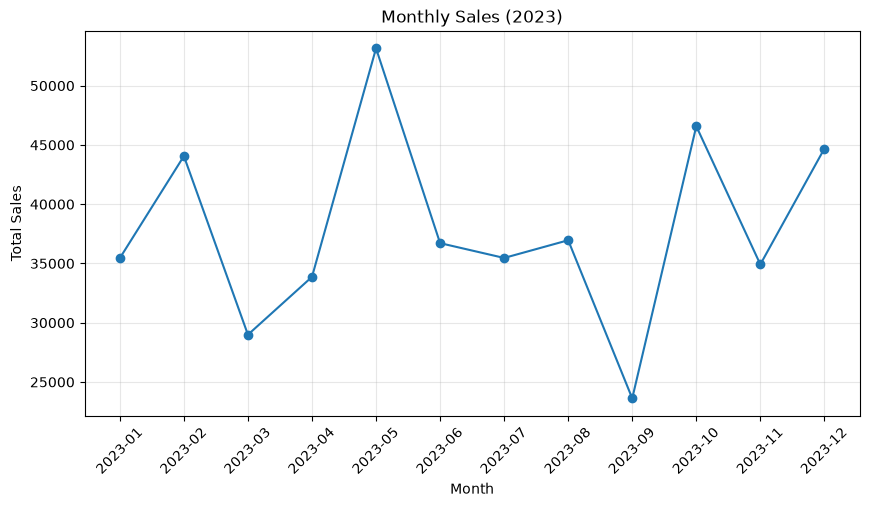

In [9]:
monthly = df.groupby("Month")["Total Amount"].sum()
monthly.index = monthly.index.astype(str)

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales (2023)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

### Monthly Sales Trend
Sales were highest in May and lowest in September. The sales do not grow steadily. They go up and down, with peaks in February, May, October and December. The year-end months look strong, which may be because of festive and holiday shopping.

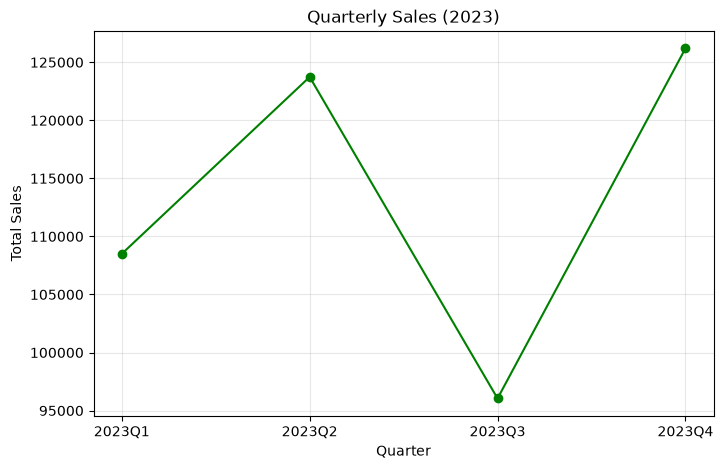

In [10]:
quarterly = df.groupby("Quarter")["Total Amount"].sum()
quarterly.index = quarterly.index.astype(str)

plt.figure(figsize=(8, 5))
plt.plot(quarterly.index, quarterly.values, marker="o", color="green")
plt.title("Quarterly Sales (2023)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(alpha=0.3)
plt.show()

### Quarterly Sales Trend
Q4 had the highest sales and Q3 had the lowest. Sales were fairly stable through the year, apart from the dip in Q3. The business could run special offers in Q3 to bring that quarter closer to the others.

In [11]:
bins = [17, 25, 35, 45, 55, 70]
labels = ["18-25", "26-35", "36-45", "46-55", "56+"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)
df["Age Group"].value_counts().sort_index()

Age Group
18-25    169
26-35    205
36-45    201
46-55    228
56+      195
Name: count, dtype: int64

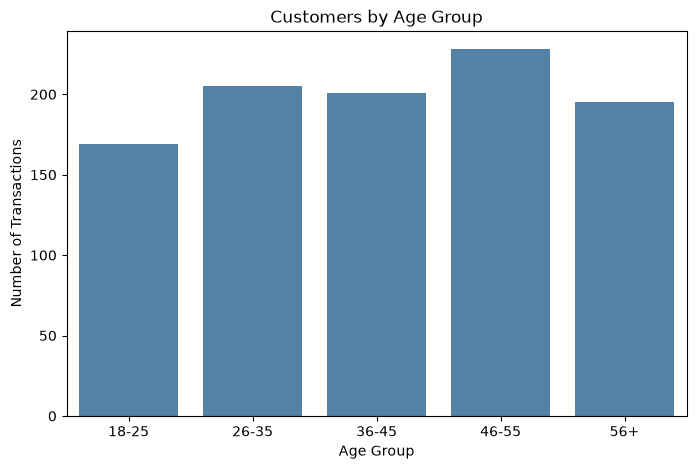

In [12]:
plt.figure(figsize=(8, 5))
sns.countplot(x="Age Group", data=df, color="steelblue")
plt.title("Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.show()

### Customers by Age Group
Customers are spread fairly evenly across all age groups. The 46-55 group has the most transactions (228), followed by 26-35 (205) and 36-45 (201). The 18-25 group has the fewest (169). This means the store does not depend on just one age group.

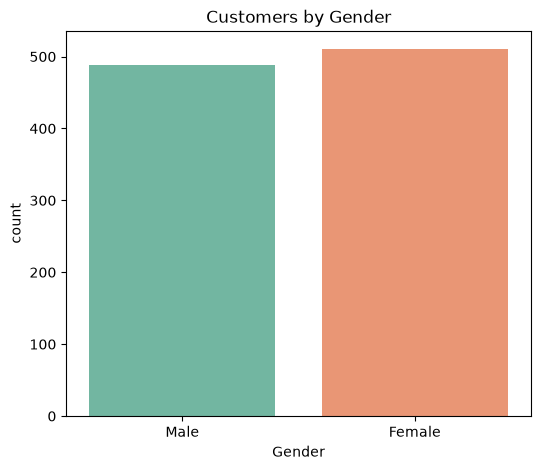

Gender
Female    51.102204
Male      48.897796
Name: proportion, dtype: float64

In [13]:
plt.figure(figsize=(6, 5))
sns.countplot(x="Gender", hue="Gender", data=df, palette="Set2", legend=False)
plt.title("Customers by Gender")
plt.show()

df["Gender"].value_counts(normalize=True) * 100

### Customers by Gender
The split between genders is almost equal: about 51% of the transactions are from female customers (510) and about 49% from male customers (488). The store attracts both genders, so marketing does not need to target only one of them.

### Product Analysis
The dataset does not have product names. So I treated each Category and Price combination as one product, like "Clothing @ 300".

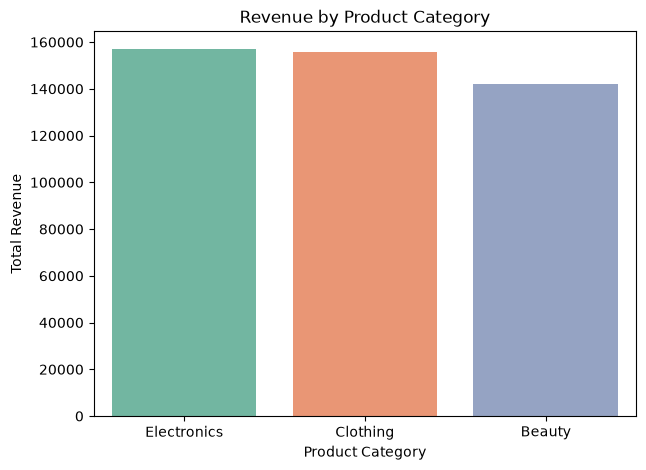

Product Category
Electronics    156875
Clothing       155580
Beauty         142015
Name: Total Amount, dtype: int64

In [14]:
cat_rev = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(7, 5))
sns.barplot(x=cat_rev.index, y=cat_rev.values, hue=cat_rev.index, palette="Set2", legend=False)
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.show()

cat_rev

### Revenue by Product Category
Electronics made the most money, and Clothing is very close behind. Beauty made the least. The three categories are quite close, so no single category is far ahead of the others.

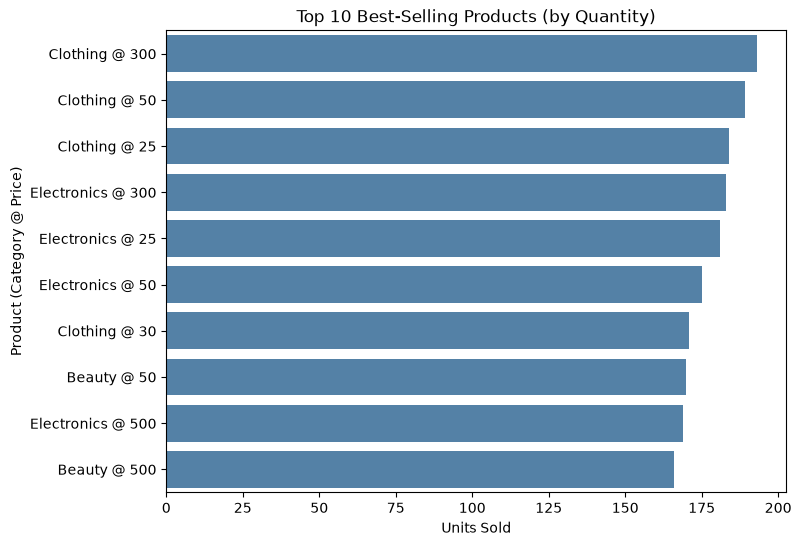

Product
Clothing @ 300       193
Clothing @ 50        189
Clothing @ 25        184
Electronics @ 300    183
Electronics @ 25     181
Electronics @ 50     175
Clothing @ 30        171
Beauty @ 50          170
Electronics @ 500    169
Beauty @ 500         166
Name: Quantity, dtype: int64

In [15]:
df["Product"] = df["Product Category"] + " @ " + df["Price per Unit"].astype(str)
top10 = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 6))
sns.barplot(x=top10.values, y=top10.index, color="steelblue")
plt.title("Top 10 Best-Selling Products (by Quantity)")
plt.xlabel("Units Sold")
plt.ylabel("Product (Category @ Price)")
plt.show()

top10

### Top 10 Best-Selling Products
Clothing at price 300 sold the most units. Clothing at 50 and Clothing at 25 come next. Clothing appears four times in the top 10, so people buy clothing at many different prices.

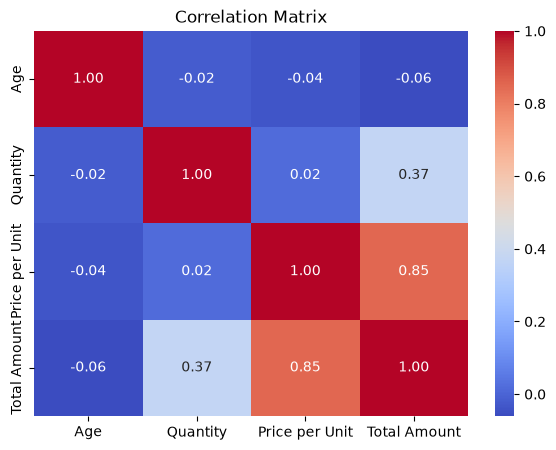

In [16]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### Correlation Heatmap
Price per Unit and Total Amount are strongly related (0.85). This means the price of the item decides the order value more than anything else. Quantity is related to Total Amount too, but less (0.37). Age has almost no link with the other columns, so a customer's age does not change how much they spend.

In [18]:
price_rev = df.groupby("Price per Unit")["Total Amount"].sum()
price_rev

Price per Unit
25      13050
30      13320
50      26700
300    155400
500    246000
Name: Total Amount, dtype: int64

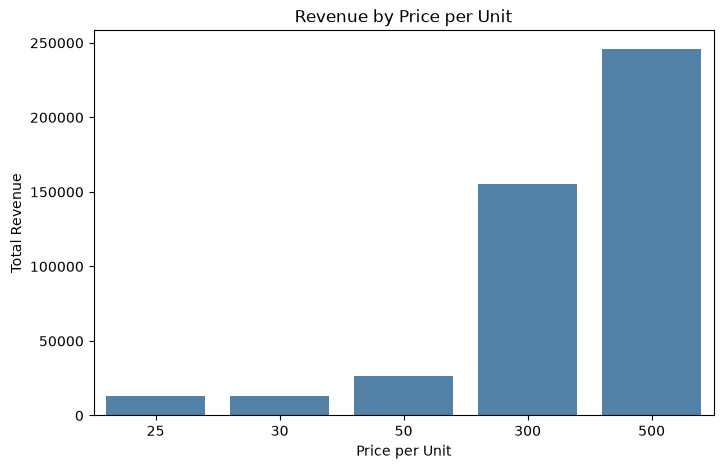

In [19]:
plt.figure(figsize=(8, 5))
sns.barplot(x=price_rev.index, y=price_rev.values, color="steelblue")
plt.title("Revenue by Price per Unit")
plt.xlabel("Price per Unit")
plt.ylabel("Total Revenue")
plt.show()

### Revenue by Price per Unit
An interesting pattern emerges from this chart: just two price points—300 and 500—account for approximately 88% of total revenue, even though they represent only about 40% of the total transactions. Conversely, lower-priced items (25, 30, and 50) make up 60% of the transactions but contribute only around 12% to the revenue. In other words, while more people purchase lower-priced items, the store’s primary revenue is generated by higher-priced products.

In [20]:
revenue_percent = price_rev / price_rev.sum() * 100
revenue_percent.round(1)

Price per Unit
25      2.9
30      2.9
50      5.9
300    34.2
500    54.1
Name: Total Amount, dtype: float64

## Conclusion and Recommendations
1. **Run offers in Q3.** Sales fell in Q3, so discounts or special offers in that period can help.
2. **Match the product to the age group.** Clothing sells well to ages 26-35 and Electronics to ages 36 and above, so ads can be planned for each group.
3. **Focus on higher-priced items.** Items priced at 300 and 500 bring about 88% of the revenue, so promoting them can raise total sales.
4. **Do not target only one gender.** Male and female customers are almost equal, so campaigns should include both.